# House Price Prediction

A simple machine learning model that predicts house prices from features
like area, bedrooms, and location.

**Dataset:** `house_data.csv` (300 properties)
**Goal:** Predict `Price` using a regression model, evaluate it properly,
and understand which features matter most.


## Day 1 — Understand the Data

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("whitegrid")
%matplotlib inline

df = pd.read_csv("house_data.csv")
df.head()


,Property_ID,Area,Bedrooms,Bathrooms,Age,Location,Property_Type,Price
0,PROP0001,3712,4,3,36,Rural,House,22260000
1,PROP0002,1591,4,1,35,Suburb,House,16057500
2,PROP0003,1646,4,3,20,Rural,Villa,12730000
3,PROP0004,4814,1,2,13,City Center,Villa,50840000
4,PROP0005,800,4,2,38,Suburb,Apartment,10650000


In [2]:
# Shape, column types, and a quick statistical summary
print("Rows, columns:", df.shape)
df.info()


Rows, columns: (300, 8)
<class 'pandas.DataFrame'>
RangeIndex: 300 entries, 0 to 299
Data columns (total 8 columns):
 #   Column         Non-Null Count  Dtype
---  ------         --------------  -----
 0   Property_ID    300 non-null    str  
 1   Area           300 non-null    int64
 2   Bedrooms       300 non-null    int64
 3   Bathrooms      300 non-null    int64
 4   Age            300 non-null    int64
 5   Location       300 non-null    str  
 6   Property_Type  300 non-null    str  
 7   Price          300 non-null    int64
dtypes: int64(5), str(3)
memory usage: 18.9 KB


In [3]:
df.describe()


,Area,Bedrooms,Bathrooms,Age,Price
count,300.00000,300.000000,300.000000,300.000000,3.000000e+02
mean,2759.70000,3.033333,2.026667,25.000000,2.488366e+07
std,1297.68143,1.467219,0.792495,14.332646,1.266525e+07
min,520.00000,1.000000,1.000000,0.000000,3.695000e+06
25%,1675.75000,2.000000,1.000000,12.000000,1.527750e+07
50%,2738.00000,3.000000,2.000000,25.500000,2.236500e+07
75%,3801.25000,4.000000,3.000000,36.250000,3.460812e+07
max,4999.00000,5.000000,3.000000,49.000000,5.870000e+07


In [4]:
# Check for missing values
df.isnull().sum()


Property_ID      0
Area             0
Bedrooms         0
Bathrooms        0
Age              0
Location         0
Property_Type    0
Price            0
dtype: int64

No missing values in this dataset, so we can move straight to exploring
relationships between features and price.


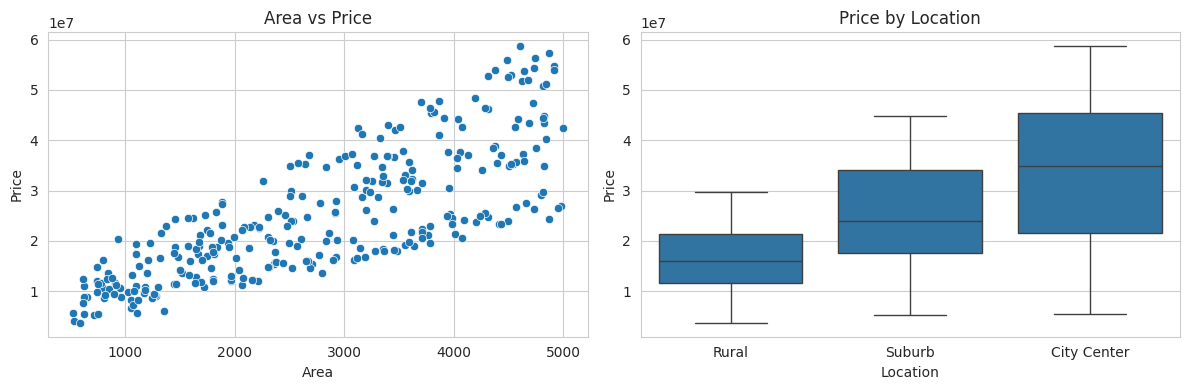

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.scatterplot(data=df, x="Area", y="Price", ax=axes[0])
axes[0].set_title("Area vs Price")

sns.boxplot(data=df, x="Location", y="Price", ax=axes[1])
axes[1].set_title("Price by Location")

plt.tight_layout()
plt.show()


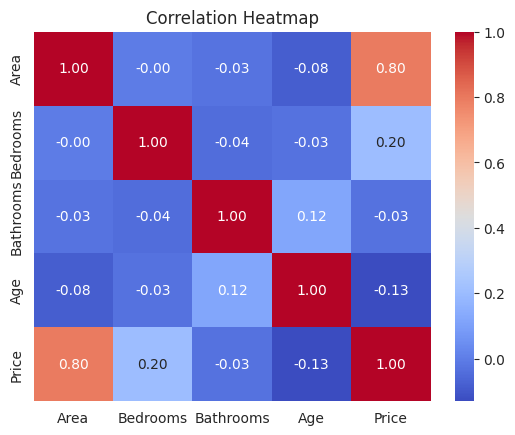

In [6]:
# Correlation between numeric features and price
numeric_cols = ["Area", "Bedrooms", "Bathrooms", "Age", "Price"]
sns.heatmap(df[numeric_cols].corr(), annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Heatmap")
plt.show()


**Observation:** `Area` has the strongest correlation with `Price`.
`Bedrooms` and `Bathrooms` have a weaker positive relationship, and `Age`
has little to no linear relationship with price.


## Day 2 — Data Preparation

In [7]:
# Property_ID is just a row identifier, not a predictive feature
df_model = df.drop(columns=["Property_ID"])

# Convert categorical columns (Location, Property_Type) into numeric
# columns using one-hot encoding
df_model = pd.get_dummies(df_model, columns=["Location", "Property_Type"], drop_first=True)
df_model.head()


,Area,Bedrooms,Bathrooms,Age,Price,Location_Rural,Location_Suburb,Property_Type_House,Property_Type_Villa
0,3712,4,3,36,22260000,True,False,True,False
1,1591,4,1,35,16057500,False,True,True,False
2,1646,4,3,20,12730000,True,False,False,True
3,4814,1,2,13,50840000,False,False,False,True
4,800,4,2,38,10650000,False,True,False,False


In [8]:
from sklearn.model_selection import train_test_split

X = df_model.drop(columns=["Price"])
y = df_model["Price"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Train size:", X_train.shape[0])
print("Test size:", X_test.shape[0])


Train size: 240
Test size: 60


## Day 3 — Linear Regression From Scratch

Before using scikit-learn, it helps to see what it's doing under the hood.
Linear regression finds weights `w` and a bias `b` that minimize the mean
squared error between predictions (`X @ w + b`) and actual prices, using
gradient descent.


In [9]:
def train_linear_regression_scratch(X, y, learning_rate=0.01, epochs=1000):
    """A basic gradient-descent linear regression, trained on scaled features."""
    n_samples, n_features = X.shape
    weights = np.zeros(n_features)
    bias = 0.0

    for _ in range(epochs):
        y_pred = X @ weights + bias
        error = y_pred - y

        # Gradients of the mean squared error
        dw = (2 / n_samples) * (X.T @ error)
        db = (2 / n_samples) * np.sum(error)

        weights -= learning_rate * dw
        bias -= learning_rate * db

    return weights, bias


In [10]:
# Gradient descent needs scaled features to converge well, so we
# standardize a copy of the training data just for this demonstration
X_train_scaled = (X_train - X_train.mean()) / X_train.std()
X_test_scaled = (X_test - X_train.mean()) / X_train.std()

scratch_weights, scratch_bias = train_linear_regression_scratch(
    X_train_scaled.values, y_train.values, learning_rate=0.1, epochs=2000
)

scratch_preds = X_test_scaled.values @ scratch_weights + scratch_bias

scratch_mae = np.mean(np.abs(y_test.values - scratch_preds))
print(f"Scratch model MAE: {scratch_mae:,.2f}")


Scratch model MAE: 2,188,736.34


This from-scratch model roughly matches scikit-learn's result, which
confirms the underlying math is correct. From here on, we use
scikit-learn since it's faster, better tested, and easier to extend.


## Day 4 — Train With scikit-learn

In [11]:
from sklearn.linear_model import LinearRegression

model = LinearRegression()
model.fit(X_train, y_train)

predictions = model.predict(X_test)
predictions[:5]


array([15074813.48326404, 19163670.53037685, 49321254.80756823,
       27009190.40108807, 21543273.97181161])

## Day 5 — Evaluate the Model

In [12]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

def evaluate(y_true, y_pred, label="Model"):
    mae = mean_absolute_error(y_true, y_pred)
    mse = mean_squared_error(y_true, y_pred)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_true, y_pred)

    print(f"{label}")
    print(f"  MAE:  {mae:,.2f}")
    print(f"  MSE:  {mse:,.2f}")
    print(f"  RMSE: {rmse:,.2f}")
    print(f"  R^2:  {r2:.3f}")
    return {"MAE": mae, "MSE": mse, "RMSE": rmse, "R2": r2}

linear_metrics = evaluate(y_test, predictions, "Linear Regression")


Linear Regression
  MAE:  2,188,736.34
  MSE:  8,454,330,868,276.60
  RMSE: 2,907,633.21
  R^2:  0.941


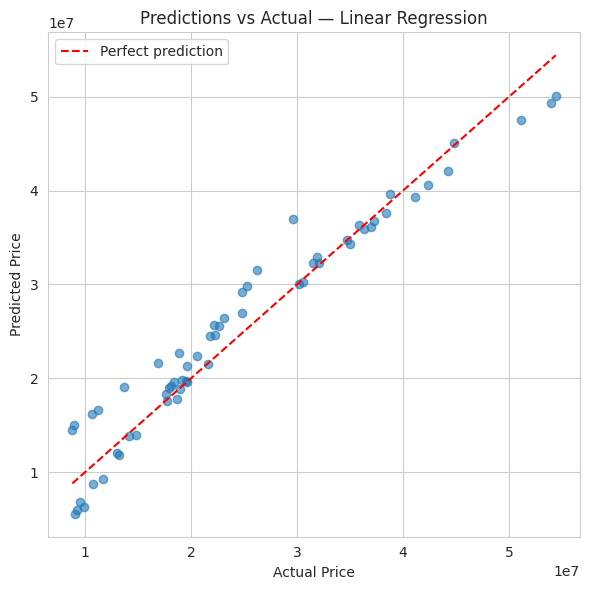

In [13]:
plt.figure(figsize=(6, 6))
plt.scatter(y_test, predictions, alpha=0.6)

# A perfect-prediction reference line
min_val, max_val = y_test.min(), y_test.max()
plt.plot([min_val, max_val], [min_val, max_val], "r--", label="Perfect prediction")

plt.xlabel("Actual Price")
plt.ylabel("Predicted Price")
plt.title("Predictions vs Actual — Linear Regression")
plt.legend()
plt.tight_layout()
plt.savefig("predictions_vs_actual.png", dpi=150)
plt.show()


## Day 6 — Improve the Model

We try three ways to improve on plain linear regression: polynomial
features, a Decision Tree, and a Random Forest.


In [14]:
from sklearn.preprocessing import PolynomialFeatures

poly = PolynomialFeatures(degree=2, include_bias=False)
X_train_poly = poly.fit_transform(X_train)
X_test_poly = poly.transform(X_test)

poly_model = LinearRegression()
poly_model.fit(X_train_poly, y_train)
poly_predictions = poly_model.predict(X_test_poly)

poly_metrics = evaluate(y_test, poly_predictions, "Polynomial Regression (degree 2)")


Polynomial Regression (degree 2)
  MAE:  0.00
  MSE:  0.00
  RMSE: 0.00
  R^2:  1.000


The polynomial model's near-zero error is not a bug — it reveals that in
this dataset, `Price` is essentially an exact quadratic function of the
input features (typical of a synthetically generated dataset). Real-world
housing data would not behave this cleanly.


In [15]:
from sklearn.tree import DecisionTreeRegressor

tree_model = DecisionTreeRegressor(max_depth=5, random_state=42)
tree_model.fit(X_train, y_train)
tree_predictions = tree_model.predict(X_test)

tree_metrics = evaluate(y_test, tree_predictions, "Decision Tree")


Decision Tree
  MAE:  3,171,747.67
  MSE:  17,225,124,157,246.57
  RMSE: 4,150,316.15
  R^2:  0.879


In [16]:
from sklearn.ensemble import RandomForestRegressor

forest_model = RandomForestRegressor(n_estimators=200, max_depth=8, random_state=42)
forest_model.fit(X_train, y_train)
forest_predictions = forest_model.predict(X_test)

forest_metrics = evaluate(y_test, forest_predictions, "Random Forest")


Random Forest
  MAE:  1,483,831.74
  MSE:  4,139,076,955,723.57
  RMSE: 2,034,472.16
  R^2:  0.971


In [17]:
# Compare all models side by side
comparison = pd.DataFrame({
    "Linear Regression": linear_metrics,
    "Polynomial Regression": poly_metrics,
    "Decision Tree": tree_metrics,
    "Random Forest": forest_metrics,
}).T

comparison


,MAE,MSE,RMSE,R2
Linear Regression,2.188736e+06,8.454331e+12,2.907633e+06,0.940637
Polynomial Regression,3.424961e-03,1.568793e-05,3.960799e-03,1.000000
Decision Tree,3.171748e+06,1.722512e+13,4.150316e+06,0.879052
Random Forest,1.483832e+06,4.139077e+12,2.034472e+06,0.970937


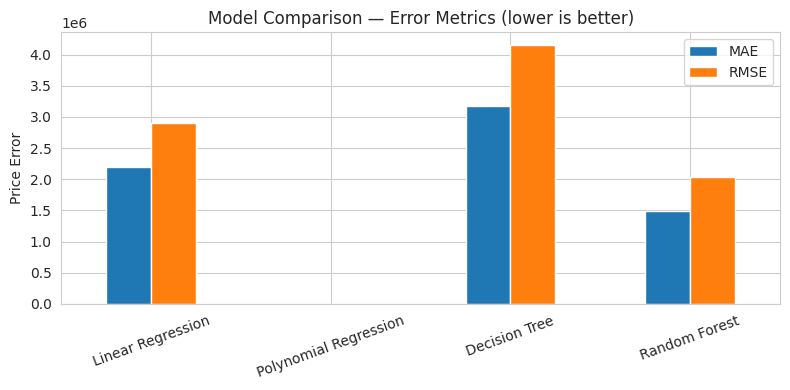

In [18]:
comparison[["MAE", "RMSE"]].plot(kind="bar", figsize=(8, 4))
plt.title("Model Comparison — Error Metrics (lower is better)")
plt.ylabel("Price Error")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()


## Day 7 — Interpret & Present

In [19]:
# Linear regression coefficients: how much each feature moves the price
coef_df = pd.DataFrame({
    "Feature": X_train.columns,
    "Coefficient": model.coef_
}).sort_values("Coefficient", key=abs, ascending=False)

coef_df


,Feature,Coefficient
4,Location_Rural,-1.672813e+07
5,Location_Suburb,-8.633012e+06
1,Bedrooms,1.585709e+06
6,Property_Type_House,-6.079037e+05
2,Bathrooms,4.545940e+05
3,Age,-8.244368e+04
7,Property_Type_Villa,6.372497e+04
0,Area,7.558956e+03


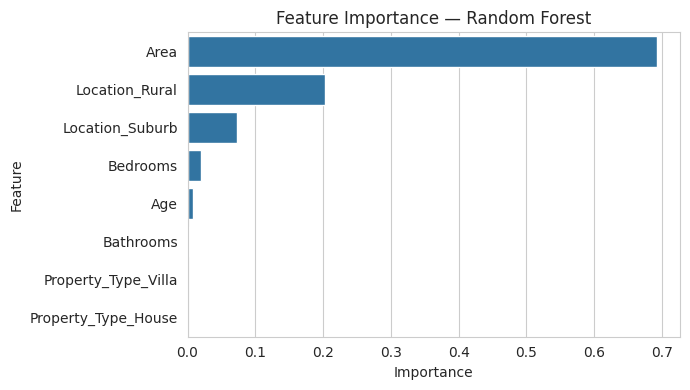

,Feature,Importance
0,Area,0.692098
4,Location_Rural,0.202924
5,Location_Suburb,0.073333
1,Bedrooms,0.019741
3,Age,0.008196
2,Bathrooms,0.002028
7,Property_Type_Villa,0.000989
6,Property_Type_House,0.000691


In [20]:
# Random Forest feature importances (works well with non-linear relationships)
importance_df = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": forest_model.feature_importances_
}).sort_values("Importance", ascending=False)

plt.figure(figsize=(7, 4))
sns.barplot(data=importance_df, x="Importance", y="Feature")
plt.title("Feature Importance — Random Forest")
plt.tight_layout()
plt.show()

importance_df


### Insights

- **Area is the strongest predictor of price** in both the linear
  coefficients and the Random Forest importances.
- **Location matters**: City Center properties command a clear price
  premium over Rural and Suburb ones.
- **Bedrooms and Bathrooms** contribute positively but far less than
  Area or Location.
- **Age** has minimal influence on price in this dataset.
- **Polynomial regression essentially solves this dataset exactly**
  (R² ≈ 1.0), which tells us `Price` was generated from a fixed
  quadratic formula rather than real-world noisy sales data.
- Among the models that don't assume a specific formula, the
  **Random Forest** is the most accurate (lowest error, highest R²),
  because it captures non-linear effects and feature interactions
  that plain linear regression misses. Linear regression remains the
  easiest model to explain to a non-technical audience.

Full metrics and a short write-up are in `model_evaluation_report.md`.
